### KNN regression: teen phone addiction dataset

import libs and load data

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [8]:
df= pd.read_csv("teen_phone_addiction_dataset.csv")
y = df["Addiction_Level"]

X = df.drop(
    columns=["Addiction_Level", "ID", "Name", "Location"]
)

display(df.head())

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


### train test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

### Prepare the features and train KNN regression

In [13]:
phone_categorical = X.select_dtypes(
    include=["object", "category", "string"]
).columns

phone_numeric = X.select_dtypes(include=["number"]).columns

phone_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), phone_numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), phone_categorical)
    ]
)

knn_regressor = Pipeline(steps=[
    ("preprocessor", phone_preprocessor),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])

knn_regressor.fit(X_train, y_train);

The preprocessing scales numeric features and encodes categorical ones. KNeighborsRegressor finds the five closest training examples and averages their Addiction_Level scores to predict a new score.

### Predict and evaluate

In [15]:
phone_predictions = knn_regressor.predict(X_test)

mae = mean_absolute_error(y_test, phone_predictions)
rmse = mean_squared_error(y_test, phone_predictions) ** 0.5
r2 = r2_score(y_test, phone_predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.738
RMSE: 1.082
R²:   0.536


### Compare actual and predicted values

In [16]:
comparison = pd.DataFrame({
    "Actual Addiction_Level": y_test,
    "Predicted Addiction_Level": phone_predictions
})

display(comparison.head(10))

,Actual Addiction_Level,Predicted Addiction_Level
1801,10.0,9.46
1190,10.0,9.90
1817,10.0,10.00
251,9.0,8.36
2505,10.0,9.94
1117,8.7,9.48
1411,4.6,8.40
2113,10.0,9.54
408,10.0,8.32
2579,10.0,9.84


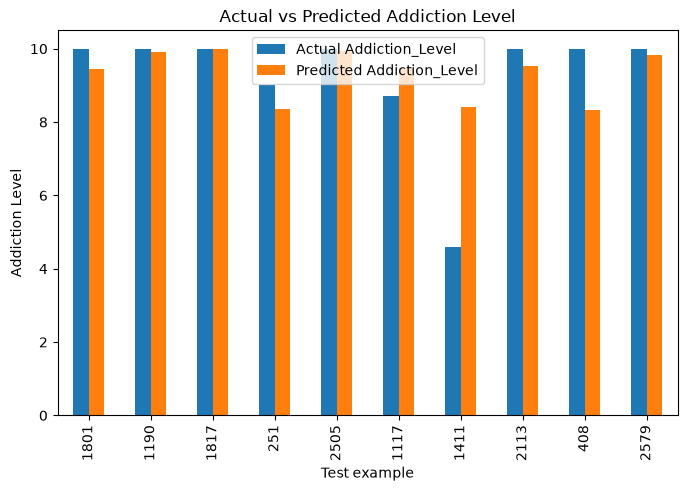

In [17]:
import matplotlib.pyplot as plt

comparison.head(10).plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Addiction Level")
plt.xlabel("Test example")
plt.ylabel("Addiction Level")
plt.show()